In [1]:
from pathlib import Path
import sys

PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_raw_data
from src.data_cleaning import clean_data
from src.feature_engineering import create_features

# Load and prepare dataset
data = load_raw_data()
data = clean_data(data)
data = create_features(data)

print("Dataset Shape:", data.shape)

Dataset Shape: (48696, 42)


In [2]:
data.describe()

,record_id,engine_cc,max_power_bhp,kerb_weight_kg,fuel_tank_l,gears,model_year,odometer_km,months_since_service,tyre_pressure_front_psi,...,rider_weight_kg,pillion,luggage_kg,trip_distance_km,mileage_kmpl,power_to_weight_ratio,engine_cc_per_kg,average_tyre_pressure,tyre_pressure_difference,speed_difference
count,48696.000000,48696.000000,48696.000000,48696.000000,48696.000000,48696.000000,48696.000000,48696.000000,48210.000000,48210.000000,...,48115.000000,48696.00000,48210.000000,48696.000000,48696.000000,48696.000000,48696.000000,47726.000000,47726.000000,48696.000000
mean,24348.500000,323.515037,32.397238,154.614116,11.803916,4.723735,2022.476384,29015.386808,4.457976,25.274964,...,72.014216,0.25692,3.174829,39.733185,21.375069,0.181642,1.842770,27.154056,-3.754159,21.527277
std,14057.468691,312.248691,35.878475,39.318408,3.680728,1.656845,2.830208,24582.248256,4.802117,4.103878,...,11.855073,0.43694,4.651673,45.814541,11.154660,0.157770,1.231625,3.075403,5.792361,9.299254
min,1.000000,97.200000,7.280000,99.000000,4.800000,1.000000,2016.000000,1200.000000,0.000000,15.000000,...,45.000000,0.00000,0.000000,2.000000,2.000000,0.067521,0.779375,15.500000,-27.000000,5.500000
25%,12174.750000,124.700000,10.590000,118.000000,10.000000,5.000000,2020.000000,10254.750000,1.000000,22.000000,...,64.000000,0.00000,0.000000,14.100000,12.950000,0.083143,1.071942,25.000000,-8.000000,14.100000
50%,24348.500000,184.400000,18.400000,148.000000,12.000000,5.000000,2023.000000,22207.500000,3.000000,25.000000,...,72.000000,0.00000,0.000000,25.600000,19.450000,0.118750,1.262626,27.000000,-4.000000,21.400000
75%,36522.250000,399.000000,39.500000,181.000000,14.000000,6.000000,2025.000000,41003.000000,6.000000,28.000000,...,80.000000,1.00000,6.200000,47.500000,27.970000,0.210651,2.221622,29.000000,0.000000,27.400000
max,48696.000000,2458.000000,200.000000,317.000000,21.000000,6.000000,2026.000000,125924.000000,24.000000,44.000000,...,120.000000,1.00000,15.000000,600.000000,75.010000,0.966184,7.753943,40.000000,20.000000,45.500000


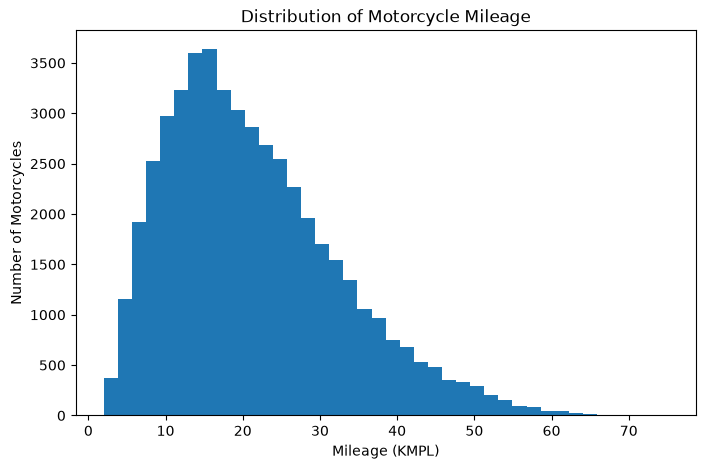

In [3]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.hist(data["mileage_kmpl"], bins=40)

plt.title("Distribution of Motorcycle Mileage")
plt.xlabel("Mileage (KMPL)")
plt.ylabel("Number of Motorcycles")

plt.show()

brand
HERO             28.170826
TVS              26.123178
BAJAJ            25.207137
HONDA            24.462924
YAMAHA           23.177648
SUZUKI           18.661258
ROYAL ENFIELD    15.265094
KTM              14.687952
KAWASAKI         12.930277
TRIUMPH          11.513503
Name: mileage_kmpl, dtype: float64


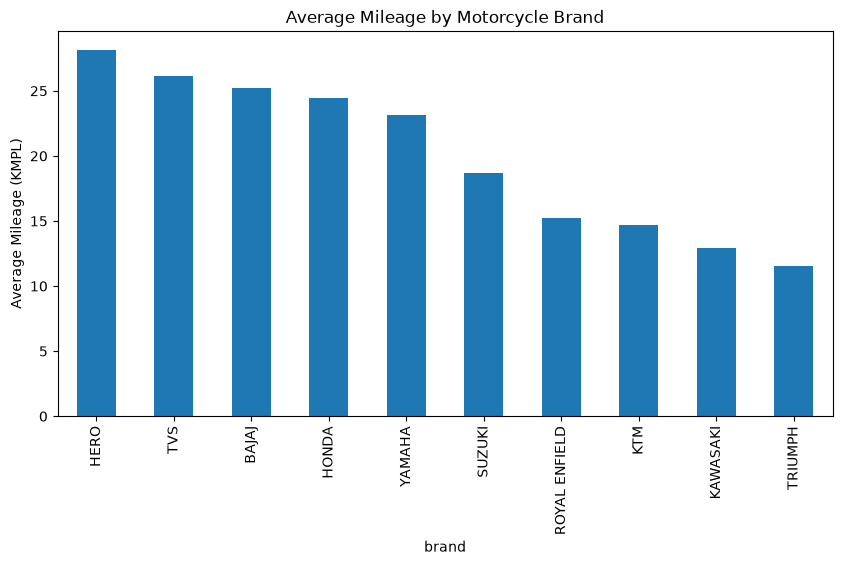

In [5]:
brand_mileage = data.groupby("brand")["mileage_kmpl"].mean()

brand_mileage = brand_mileage.sort_values(ascending=False)

print(brand_mileage)

brand_mileage.plot(
    kind="bar",
    figsize=(10, 5),
    title="Average Mileage by Motorcycle Brand"
)

plt.ylabel("Average Mileage (KMPL)")
plt.show()

In [16]:
# ==========================================
# FEATURE CORRELATION ANALYSIS
# ==========================================

# 1. Remove target and ID columns
X = data.drop(
    columns=["mileage_kmpl", "record_id"]
)

# 2. Select numerical columns
numerical_data = X.select_dtypes(
    include=["number"]
)

# 3. Calculate correlation between features
correlation = numerical_data.corr()

# 4. Find highly correlated feature pairs
print("Highly Correlated Feature Pairs")
print("--------------------------------")

for i in range(len(correlation.columns)):

    for j in range(i + 1, len(correlation.columns)):

        value = correlation.iloc[i, j]

        if abs(value) > 0.85:

            feature_1 = correlation.columns[i]
            feature_2 = correlation.columns[j]

            print(
                feature_1,
                "and",
                feature_2,
                "=", round(value, 3)
            )

Highly Correlated Feature Pairs
--------------------------------
engine_cc and max_power_bhp = 0.915
engine_cc and power_to_weight_ratio = 0.856
engine_cc and engine_cc_per_kg = 0.978
max_power_bhp and power_to_weight_ratio = 0.983
max_power_bhp and engine_cc_per_kg = 0.933
avg_speed_kmph and max_speed_kmph = 0.927
power_to_weight_ratio and engine_cc_per_kg = 0.907
